# Figure 9. The impulse-variability equation as a static case of the dynamic law

**What it is.** The nine effective widths of Schmidt et al. (1979) with their line, the spread of force over the shares, and the correlation that keeps the slope.

**How it works.** Reads the nine values and the shares of the simulated performer, fits the line and evaluates Equation 22.

**Files read.** `data/read_from_figures/schmidt1979_fig8_fig9_distance_We.csv`, `sim_out/sim_static_cases.npz`, `figures/style.py`, `code/force_spread.py`.

**To run.** Open this notebook from the `notebooks` folder of the repository, or from its root, and run all cells.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
import logging, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
logging.getLogger("matplotlib").setLevel(logging.ERROR)
plt.ioff()
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "figures"), str(ROOT / "code")]

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

from style import Sheet, INK, GREY, EDGE, RULE, TONE, share_colour, demand_colour, tb_axes, CLEAR

import force_spread as fs

src = ROOT / "sim_out"
d = np.load(src / "sim_static_cases.npz")
N = fs.N
p1 = np.sort(d["p1000"])[::-1]
p0 = np.full(N, 1.0 / N)
S0, S1 = 1.0 / N, float((p1 ** 2).sum())
R_KEEP = fs.rbar_for(1.0, S1)
z = pd.read_csv(ROOT / "data" / "read_from_figures" / "schmidt1979_fig8_fig9_distance_We.csv")
b0, a0 = np.polyfit(z.A_over_MT_fig9_cm_s, z.We_mm_fig9, 1)
assert abs(a0 - 2.249) < 0.001 and abs(b0 - 0.0303) < 0.0001

S = Sheet(6.5, 1.94)
axA = S.ax(1.94, 0.20, 2.30, 1.50)
axB = S.ax(0.42, 0.42, 1.44, 1.26)
axC = S.ax(4.86, 0.42, 1.44, 1.26)
OPEN = TONE["small-world"]

## B, the force shared among the elements

In [3]:
ax = axA
ax.set_xlim(0, 10)
ax.set_ylim(0, 6.5)
ax.axis("off")
X0, WBAR, HBAR = 0.3, 4.4, 0.62

def bar(y, p, label):
    x = X0
    for pi in p:
        if pi <= 0:
            continue
        ax.add_patch(Rectangle((x, y), WBAR * pi, HBAR, fc=share_colour(np.log2(pi * N)), ec=EDGE, lw=0.3,
                               zorder=3 + pi))
        x += WBAR * pi
    ax.text(X0, y + HBAR + 0.22, label, fontsize=6.6, ha="left", va="bottom")

def curve(xc, y, sd, **kw):
    """A normal density of unit area for the summed force, sd in units of kappa, drawn on the baseline y."""
    u = np.linspace(-1.05, 1.05, 160)
    fill = kw.pop("fill", None)
    if fill is not None:
        ax.fill_between(xc + 1.55 * u, y, y + 0.13 * np.exp(-0.5 * (u / sd) ** 2) / sd, color=fill, lw=0, zorder=1)
    ax.plot(xc + 1.55 * u, y + 0.13 * np.exp(-0.5 * (u / sd) ** 2) / sd, **kw)

bar(4.55, p0, "step 0, even shares")
bar(1.75, p1, "step 1,000, shares of the simulated performer")
XC, XL = 6.35, 8.15
for y in (4.55, 1.75):
    ax.plot([XC - 1.65, XC + 1.65], [y, y], color=EDGE, lw=0.5)
curve(XC, 4.55, fs.spread(S0, 0.0), color=INK, lw=0.9, fill=share_colour(0.0))
curve(XC, 1.75, fs.spread(S1, 0.0), color=OPEN, lw=0.9, ls=(0, (3.0, 1.6)))
curve(XC, 1.75, fs.spread(S1, R_KEEP), color=INK, lw=0.9, fill=share_colour(0.0))
mn = lambda v: f"{v:.2f}".replace("-", "\u2212")
ax.text(XL, 4.55 + 0.42, rf"$\bar r$ = 0, {fs.spread(S0, 0.0):.2f}$\kappa$", fontsize=6.2, ha="left", va="center")
ax.text(XL, 1.75 + 0.56, rf"$\bar r$ = {mn(R_KEEP)}, {fs.spread(S1, R_KEEP):.2f}$\kappa$", fontsize=6.2, ha="left",
        va="center")
ax.text(XL, 1.75 + 0.08, rf"$\bar r$ = 0, {fs.spread(S1, 0.0):.2f}$\kappa$", fontsize=6.2, ha="left", va="center",
        color=OPEN)
ax.text(XC + 0.6, 5.95, r"spread of the force, $\sigma_F/F$", fontsize=6.4, ha="center", va="center", color=GREY)
ax.text(4.6, 0.55, r"$\sigma_F/F = \kappa\,[\,\Sigma_i\,p_i^2 + (1 - \Sigma_i\,p_i^2)\,\bar r\,]^{1/2}$", fontsize=7.0,
        ha="center", va="center")

## A, Schmidt et al. (1979), the static case

In [4]:
ax = axB
v = np.linspace(0, 225, 20)
ax.plot(v, 2.12 + 0.033 * v, color=OPEN, lw=0.9, ls=(0, (3.0, 1.6)), zorder=2)
ax.plot(v, a0 + b0 * v, color=INK, lw=1.0, zorder=2)
SHAPE = {200: "o", 170: "s", 140: "^"}
for mt, mk in SHAPE.items():
    g = z[z.MT_ms == mt]
    for vi, wi, ci in zip(g.A_over_MT_fig9_cm_s, g.We_mm_fig9, demand_colour(g.A_over_MT_fig9_cm_s, 50, 210)):
        ax.plot(vi, wi, mk, ms=3.2 if mk != "^" else 3.5, mfc=ci, mec=EDGE, mew=0.45, zorder=3)
ax.legend(handles=[Line2D([], [], ls="", marker=SHAPE[mt], ms=2.8, mfc="white", mec=EDGE, mew=0.6) for mt in SHAPE]
          + [Line2D([], [], color=OPEN, lw=0.9, ls=(0, (3.0, 1.6))), Line2D([], [], color=INK, lw=1.0)],
          labels=["200 ms", "170 ms", "140 ms", "authors’ line", "law, step 0"], loc="upper left",
          bbox_to_anchor=(-0.02, 0.86), fontsize=5.9, handletextpad=0.3, borderaxespad=0.1, labelspacing=0.12,
          handlelength=1.4)
ax.text(2, 10.3, rf"$W_e$ = {a0:.2f} + {b0:.3f} $D/MT$", fontsize=6.6, ha="left", **CLEAR)
tb_axes(ax, xticks=[0, 100, 200], xlim=(0, 230), yticks=[0, 5, 10], ylim=(0, 11.0))
ax.set_xlabel(r"average velocity $D/MT$, cm/s", labelpad=1)
ax.set_ylabel(r"spread $W_e$, mm", labelpad=1.5)

## C, concentration and offsetting errors

In [5]:
ax = axC
h2 = np.linspace(1.0, 4.5, 300)
rb = np.linspace(-0.5, 0.2, 300)
HH, RR = np.meshgrid(h2, rb)
SS = 2.0 ** -HH
inner = SS + (1 - SS) * RR
Q = np.sqrt(np.where(inner > 0, inner, np.nan) / S0)
cs = ax.contour(HH, RR, Q, levels=[0.5, 2.0], colors=[OPEN], linewidths=0.6, linestyles=[(0, (3.0, 1.6))])
ax.clabel(cs, fmt=lambda q: f"{q:g}", fontsize=5.8, inline=True, inline_spacing=2, colors=INK,
          manual=[(2.9, -0.140), (3.9, 0.143)])
c1 = ax.contour(HH, RR, Q, levels=[1.0], colors=[INK], linewidths=1.0)
ax.clabel(c1, fmt=lambda q: "1", fontsize=5.8, inline=True, inline_spacing=2, colors=INK, manual=[(1.9, -0.298)])
H2_0, H2_1 = -np.log2(S0), -np.log2(S1)
ax.annotate("", xy=(H2_1 + 0.05, 0.0), xytext=(H2_0 - 0.08, 0.0),
            arrowprops=dict(arrowstyle="-|>", mutation_scale=6, lw=0.8, color=INK), zorder=5)
ax.annotate("", xy=(H2_1, R_KEEP + 0.018), xytext=(H2_1, -0.018),
            arrowprops=dict(arrowstyle="-|>", mutation_scale=6, lw=0.8, color=INK), zorder=5)
ax.plot(H2_0, 0.0, "o", ms=4.0, color=share_colour(0.0), mec=EDGE, mew=0.6, zorder=6)
ax.plot(H2_1, 0.0, "o", ms=3.6, mfc="white", mec=INK, mew=0.7, zorder=6)
ax.plot(H2_1, R_KEEP, "o", ms=3.4, color=INK, mec="white", mew=0.4, zorder=6)
ax.text(H2_0, 0.035, "step 0", fontsize=6.2, ha="center", va="bottom")
ax.text(H2_1, 0.035, "step 1,000", fontsize=6.2, ha="center", va="bottom")
ax.text((H2_0 + H2_1) / 2, 0.035, "practice", fontsize=6.2, ha="center", va="bottom")
ax.text(H2_1 - 0.1, R_KEEP, f"{R_KEEP:.2f}".replace("-", "−"), fontsize=6.2, ha="right", va="center", **CLEAR)
tb_axes(ax, xticks=[1, 2.75, 4.5], xlim=(1.0, 4.5), yticks=[-0.5, -0.15, 0.2], ylim=(-0.5, 0.2))
ax.set_xlabel(r"concentration $H_2$, bits", labelpad=1)
ax.set_ylabel(r"share-weighted correlation $\bar r$", labelpad=1.5)

S.head("B", "Spread of force over the shares", 1.94 + 2.30 / 2)
S.head_over(axB, "A", "Schmidt et al. (1979)")
S.head_over(axC, "C", "Concentration and offsetting errors")

print(f"line through the values W_e = {a0:.3f} + {b0:.4f} D/MT; sum p^2 {S0:.4f} -> {S1:.4f}, H_2 {H2_0:.3f} -> "
      f"{H2_1:.3f} bits; spread {fs.spread(S0, 0):.4f} -> {fs.spread(S1, 0):.4f} kappa with independent errors; "
      f"rbar keeping the slope {R_KEEP:.4f}")

line through the values W_e = 2.249 + 0.0303 D/MT; sum p^2 0.0500 -> 0.1841, H_2 4.322 -> 2.441 bits; spread 0.2236 -> 0.4291 kappa with independent errors; rbar keeping the slope -0.1644


## The figure

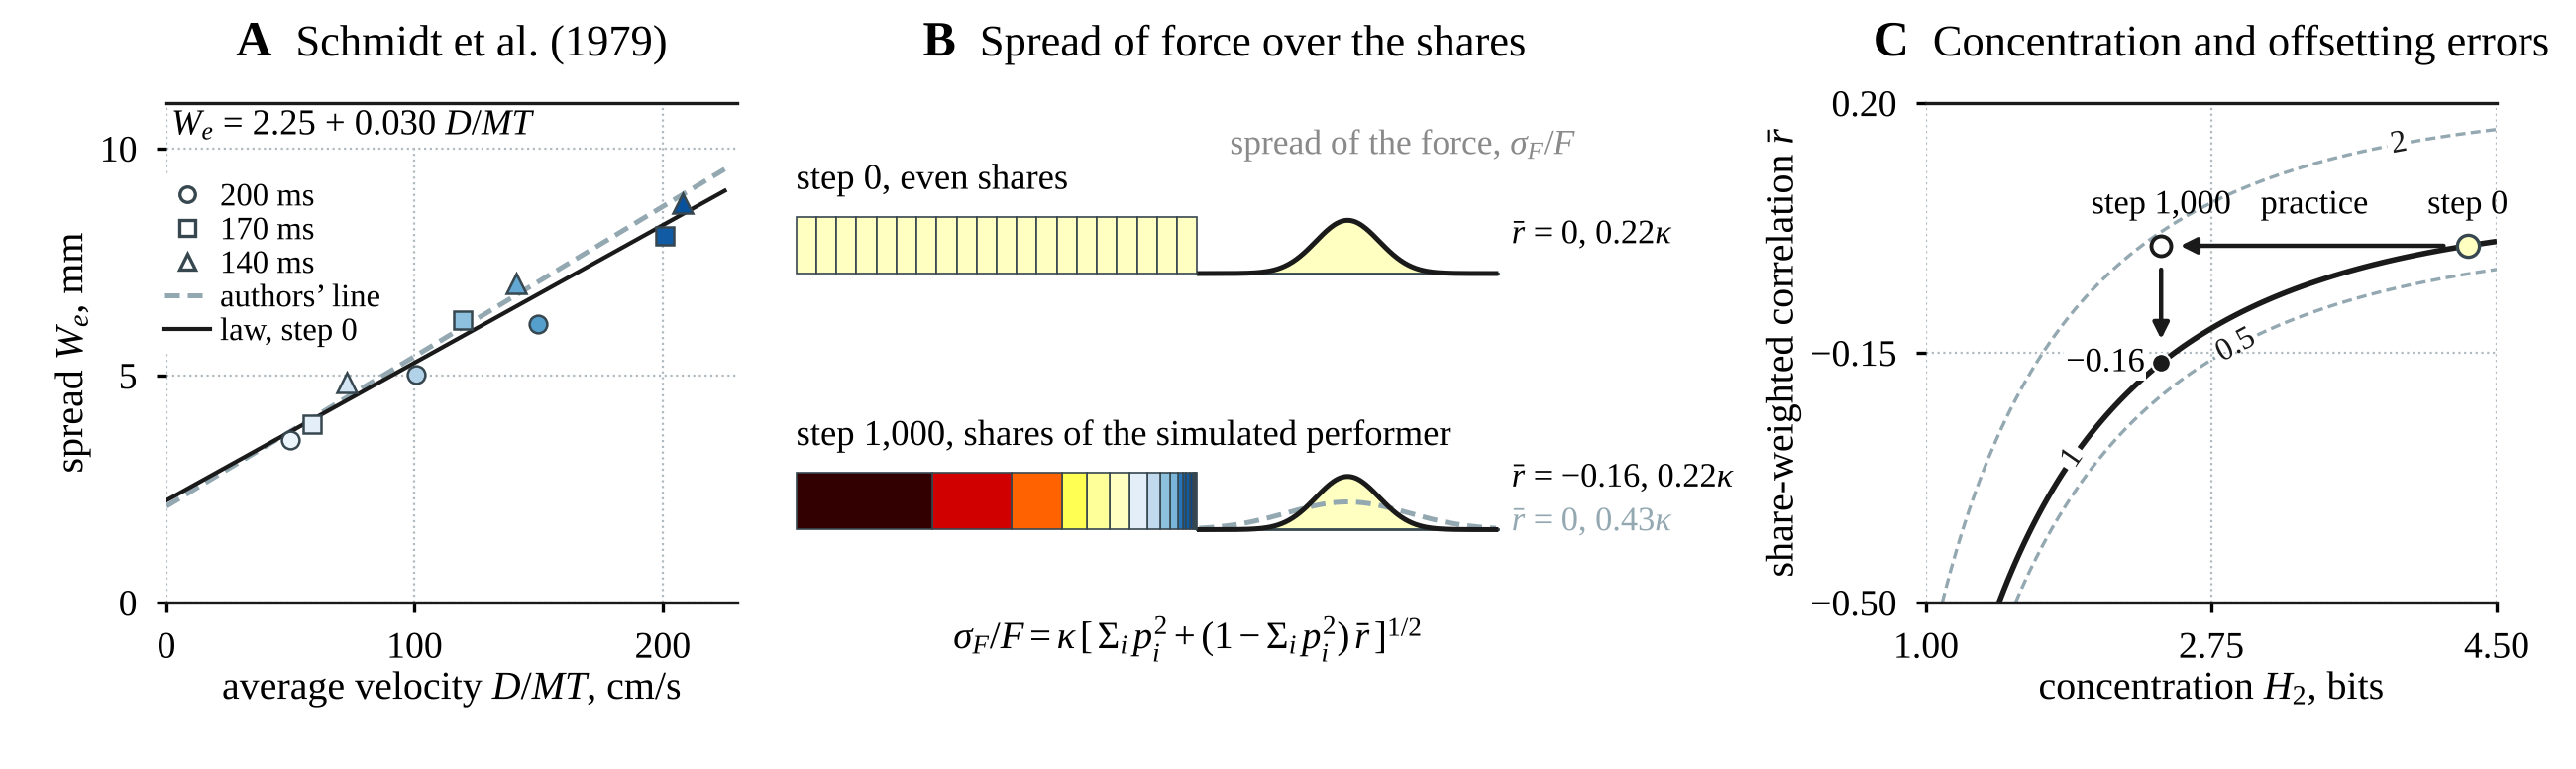

In [6]:
from style import bolden
bolden(S.fig)
display(S.fig)
plt.close("all")

## In the paper

Printed here, then as the manuscript or the Supplemental Material gives it.

- `W_e = 2.249 + 0.0303 D/MT`: W_e = 2.25 + 0.030 D/MT.
- `rbar keeping the slope -0.1644`: r̄ = −0.16.